# 06. Exploratory Data Analysis (EDA) - Curah Hujan (Malaysia & Hawaii)

Notebook ini menganalisis dataset **Curah Hujan (Presipitasi)** untuk dua wilayah observasi strategis:
1. **Benua Maritim / Pasifik Barat**: Malaysia (data dekadal CHIRPS / stasiun, 2015–2025).
2. **Pasifik Tengah**: Kepulauan Hawaii (132 file observasi stasiun harian jaringan pemantauan, 2015–2025).

### Latar Belakang Ilmiah & Telekoneksi Pasifik:
- Sirkulasi Walker tropis mengontrol distribusi konveksi dan curah hujan di sepanjang ekuator Pasifik:
  - **Kondisi Normal / La Niña**: Cabang udara naik (*ascending limb*) terpusat kuat di atas Benua Maritim (Indonesia–Malaysia), memicu curah hujan konvektif lebat, sementara Pasifik Tengah relatif lebih kering.
  - **Kondisi El Niño**: Kolam air hangat (*Warm Pool*) bergeser ke Pasifik Tengah–Timur, membawa serta pusat awan konveksi. Akibatnya, Benua Maritim (Malaysia) mengalami defisit curah hujan parah / kekeringan, sedangkan Pasifik Tengah (wilayah sekitar Hawaii) mengalami pergeseran dinamika presipitasi dan badai tropis.
- Analisis komparatif ini menguji hipotesis kopling iklim makro (*macro-climate coupling*) antara Pasifik Barat dan Pasifik Tengah pada periode **2015–2025**.

### Tujuan & Alur Eksekusi:
1. Mengekstraksi dan mengagregasi 132 file stasiun harian Hawaii menjadi deret bulanan, serta mengekspor `hawaii_15to25.csv`.
2. Mengekstraksi dan mengagregasi data presipitasi Malaysia dekadal (2015–2025) menjadi deret bulanan, serta mengekspor `malaysia_15to25.csv`.
3. Memvisualisasikan perbandingan deret waktu presipitasi bulanan Malaysia vs Hawaii (2015–2025).
4. Menganalisis siklus musiman (*seasonality*): Regime Monsun Asia Tenggara vs Regime Angin Pasat (*Trade Winds*) Pasifik Tengah.
5. Mengevaluasi distribusi anomali dan kejadian hujan ekstrem (periode defisit kekeringan vs kebasahan berlebih).
6. Menguji telekoneksi ENSO: Menghubungkan anomali curah hujan dengan indeks Oceanic Niño Index (ONI).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# Konfigurasi Path
DATA_DIR_RAIN = Path("dataset/data_rainfall") if Path("dataset/data_rainfall").exists() else Path("../dataset/data_rainfall")
DATA_DIR_ONI = Path("dataset/data_oni") if Path("dataset/data_oni").exists() else Path("../dataset/data_oni")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HAWAII_DIR = DATA_DIR_RAIN / "Hawaii"
CSV_MALAYSIA = DATA_DIR_RAIN / "Malaysia.csv"
CSV_ONI = DATA_DIR_ONI / "oni.csv"

OUT_HAWAII_CSV = DATA_DIR_RAIN / "hawaii_15to25.csv"
OUT_MALAYSIA_CSV = DATA_DIR_RAIN / "malaysia_15to25.csv"

print(f"Path dataset Rainfall: {DATA_DIR_RAIN.resolve()}")
print(f"Hawaii folder: {HAWAII_DIR.resolve()}")
print(f"Malaysia file: {CSV_MALAYSIA.resolve()}")
print(f"Output figures: {OUTPUT_DIR.resolve()}")

Path dataset Rainfall: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_rainfall
Hawaii folder: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_rainfall\Hawaii
Malaysia file: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_rainfall\Malaysia.csv
Output figures: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures


## 2. Ekstraksi & Agregasi Data Presipitasi Hawaii (2015–2025)

Direktori Hawaii memuat 132 file CSV bulanan (rentang 11 tahun: 2015 s.d. 2025).
Setiap file berisi data observasi stasiun jaringan di seluruh pulau Hawaii:
- Kolom metadata: `SKN`, `Station.Name`, `LAT`, `LON`, `ELEV.m.`, dll.
- Kolom tanggal harian: Format `X<YYYY>.<MM>.<DD>`.

Langkah pra-pemrosesan:
1. Membaca 132 file CSV secara berurutan.
2. Menghitung rata-rata spasial presipitasi seluruh stasiun untuk setiap hari.
3. Mengagregasikan curah hujan harian menjadi total bulanan (mm/bulan) untuk periode 2015–2025.
4. Menyimpan hasil olahan ke `hawaii_15to25.csv`.

In [2]:
hawaii_files = sorted(list(HAWAII_DIR.glob("*/*.csv")))
print(f"Ditemukan {len(hawaii_files)} file observasi Hawaii (2015–2025).")

daily_records = []
for file_path in hawaii_files:
    df_temp = pd.read_csv(file_path)
    date_cols = [c for c in df_temp.columns if c.startswith('X')]
    daily_means = df_temp[date_cols].mean(axis=0, skipna=True)
    for col_name, val in daily_means.items():
        date_str = col_name[1:].replace('.', '-')
        daily_records.append({'date': date_str, 'rainfall_hawaii_mean_mm': val})

df_hawaii_daily = pd.DataFrame(daily_records)
df_hawaii_daily['date'] = pd.to_datetime(df_hawaii_daily['date'])
df_hawaii_daily = df_hawaii_daily.sort_values('date').reset_index(drop=True)

# Agregasi ke bulanan (Month-Period)
df_hawaii_daily['YearMonth'] = df_hawaii_daily['date'].dt.to_period('M')
df_hawaii_monthly = df_hawaii_daily.groupby('YearMonth')['rainfall_hawaii_mean_mm'].agg(['mean', 'sum']).reset_index()
df_hawaii_monthly.columns = ['YearMonth', 'rainfall_hawaii_daily_avg', 'rainfall_hawaii_monthly_total']
df_hawaii_monthly['date'] = df_hawaii_monthly['YearMonth'].dt.to_timestamp()

# Simpan ke CSV output
df_hawaii_monthly[['date', 'rainfall_hawaii_daily_avg', 'rainfall_hawaii_monthly_total']].to_csv(OUT_HAWAII_CSV, index=False)
print(f"Output Hawaii berhasil disimpan: {OUT_HAWAII_CSV.resolve()} ({len(df_hawaii_monthly)} bulan)")
display(df_hawaii_monthly.head())

Ditemukan 132 file observasi Hawaii (2015–2025).


Output Hawaii berhasil disimpan: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_rainfall\hawaii_15to25.csv (132 bulan)


,YearMonth,rainfall_hawaii_daily_avg,rainfall_hawaii_monthly_total,date
0,2015-01,3.053336,94.653420,2015-01-01
1,2015-02,3.037683,85.055127,2015-02-01
2,2015-03,4.935172,152.990320,2015-03-01
3,2015-04,5.660663,169.819877,2015-04-01
4,2015-05,4.620560,143.237366,2015-05-01


## 3. Ekstraksi & Agregasi Data Presipitasi Malaysia (2015–2025)

Dataset Malaysia memuat data dekadal presipitasi:
- Kolom: `date`, `adm_level`, `adm_id`, `PCODE`, `rfh` (curah hujan dekad dalam mm), `rfh_avg`, dll.
- Setiap bulan terdiri dari 3 dekad (tanggal 1, 11, dan 21).

Langkah pra-pemrosesan:
1. Memfilter rentang waktu proyek: `2015-01-01` s.d. `2025-12-31`.
2. Menggunakan agregasi level regional negara bagian (`adm_level == 1`).
3. Menghitung rata-rata curah hujan dekad nasional, kemudian menjumlahkannya menjadi total bulanan.
4. Menyimpan hasil olahan ke `malaysia_15to25.csv`.

In [3]:
df_my = pd.read_csv(CSV_MALAYSIA)
df_my['date'] = pd.to_datetime(df_my['date'])

# Filter periode 2015 s.d. 2025 dan adm_level == 1
df_my_sub = df_my[(df_my['date'] >= '2015-01-01') & (df_my['date'] <= '2025-12-31') & (df_my['adm_level'] == 1)].copy()

# Rata-rata nasional per dekad
df_my_dekad = df_my_sub.groupby('date')['rfh'].mean().reset_index()
df_my_dekad['YearMonth'] = df_my_dekad['date'].dt.to_period('M')

# Agregasi ke bulanan (penjumlahan dekad dalam 1 bulan)
df_my_monthly = df_my_dekad.groupby('YearMonth')['rfh'].agg(['mean', 'sum']).reset_index()
df_my_monthly.columns = ['YearMonth', 'rainfall_malaysia_dekad_avg', 'rainfall_malaysia_monthly_total']
df_my_monthly['date'] = df_my_monthly['YearMonth'].dt.to_timestamp()

# Simpan ke CSV output
df_my_monthly[['date', 'rainfall_malaysia_dekad_avg', 'rainfall_malaysia_monthly_total']].to_csv(OUT_MALAYSIA_CSV, index=False)
print(f"Output Malaysia berhasil disimpan: {OUT_MALAYSIA_CSV.resolve()} ({len(df_my_monthly)} bulan)")
display(df_my_monthly.head())

Output Malaysia berhasil disimpan: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_rainfall\malaysia_15to25.csv (132 bulan)


,YearMonth,rainfall_malaysia_dekad_avg,rainfall_malaysia_monthly_total,date
0,2015-01,60.025098,180.075294,2015-01-01
1,2015-02,23.995677,71.987032,2015-02-01
2,2015-03,40.314595,120.943786,2015-03-01
3,2015-04,77.587692,232.763076,2015-04-01
4,2015-05,71.535866,214.607599,2015-05-01


## 4. Perbandingan Deret Waktu Presipitasi Bulanan Malaysia vs Hawaii (2015–2025)

Kita menggabungkan kedua time series bulanan yang telah diselaraskan.
Di bawah ini disajikan perbandingan kurva curah hujan bulanan absolut (dual axis) dan anomali terstandardisasi ($Z	ext{-score}$).

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\33_rainfall_timeseries_malaysia_hawaii.png


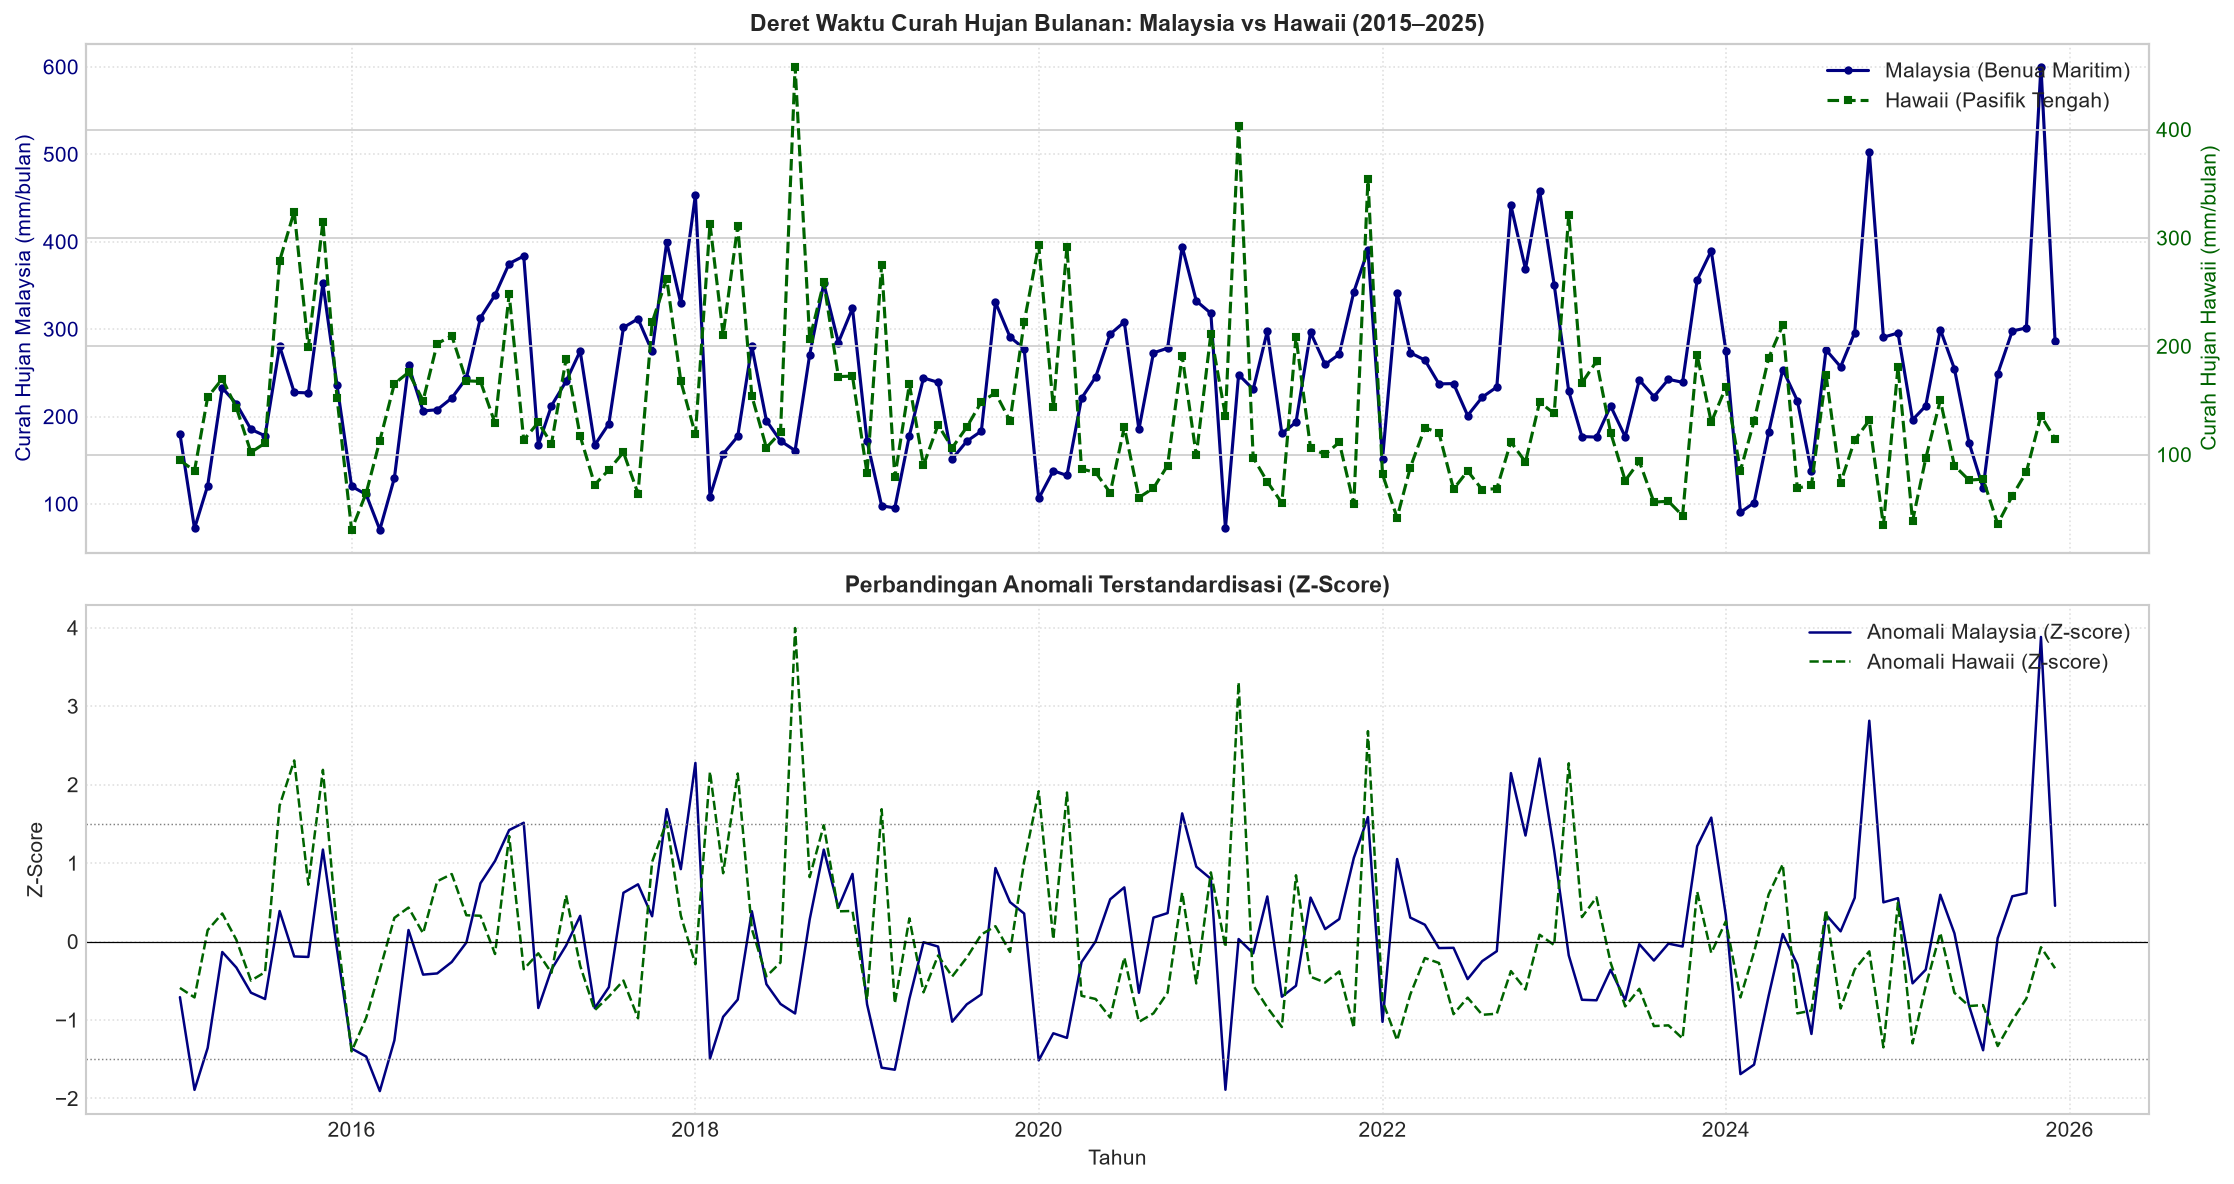

In [4]:
# Merge kedua dataset bulanan
df_rain_merged = pd.merge(
    df_my_monthly[['date', 'rainfall_malaysia_monthly_total']],
    df_hawaii_monthly[['date', 'rainfall_hawaii_monthly_total']],
    on='date',
    how='inner'
)

# Standardisasi Z-score untuk perbandingan fluktuasi relatif
df_rain_merged['Z_Malaysia'] = (df_rain_merged['rainfall_malaysia_monthly_total'] - df_rain_merged['rainfall_malaysia_monthly_total'].mean()) / df_rain_merged['rainfall_malaysia_monthly_total'].std()
df_rain_merged['Z_Hawaii'] = (df_rain_merged['rainfall_hawaii_monthly_total'] - df_rain_merged['rainfall_hawaii_monthly_total'].mean()) / df_rain_merged['rainfall_hawaii_monthly_total'].std()

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Plot 1: Dual-Axis Curah Hujan Bulanan Absolut (mm/bulan)
ax1 = axes[0]
line1 = ax1.plot(df_rain_merged['date'], df_rain_merged['rainfall_malaysia_monthly_total'],
                 color='navy', linewidth=1.5, marker='o', markersize=3, label='Malaysia (Benua Maritim)')
ax1.set_ylabel("Curah Hujan Malaysia (mm/bulan)", color='navy', fontsize=10)
ax1.tick_params(axis='y', labelcolor='navy')

ax2 = ax1.twinx()
line2 = ax2.plot(df_rain_merged['date'], df_rain_merged['rainfall_hawaii_monthly_total'],
                 color='darkgreen', linewidth=1.5, marker='s', markersize=3, linestyle='--', label='Hawaii (Pasifik Tengah)')
ax2.set_ylabel("Curah Hujan Hawaii (mm/bulan)", color='darkgreen', fontsize=10)
ax2.tick_params(axis='y', labelcolor='darkgreen')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', framealpha=0.9)
ax1.set_title("Deret Waktu Curah Hujan Bulanan: Malaysia vs Hawaii (2015–2025)", fontsize=11, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot 2: Z-Score Anomali Terstandardisasi
axes[1].plot(df_rain_merged['date'], df_rain_merged['Z_Malaysia'], color='navy', linewidth=1.2, label='Anomali Malaysia (Z-score)')
axes[1].plot(df_rain_merged['date'], df_rain_merged['Z_Hawaii'], color='darkgreen', linewidth=1.2, linestyle='--', label='Anomali Hawaii (Z-score)')
axes[1].axhline(0, color='black', linestyle='-', linewidth=0.6)
axes[1].axhline(1.5, color='gray', linestyle=':', linewidth=0.7)
axes[1].axhline(-1.5, color='gray', linestyle=':', linewidth=0.7)
axes[1].set_title("Perbandingan Anomali Terstandardisasi (Z-Score)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Z-Score", fontsize=10)
axes[1].set_xlabel("Tahun", fontsize=10)
axes[1].legend(loc='upper right', framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig_path_33 = OUTPUT_DIR / "33_rainfall_timeseries_malaysia_hawaii.png"
plt.savefig(fig_path_33)
print(f"Gambar disimpan di: {fig_path_33.resolve()}")
plt.show()

## 5. Analisis Siklus Musiman (Monsoon vs Trade Winds)

Dinamika iklim kedua wilayah memiliki penggerak musiman yang sangat kontras:
- **Malaysia (Monsun Asia–Australia)**:
  - Mengalami puncak curah hujan signifikan pada akhir tahun (November–Desember) seiring datangnya Monsun Timur Laut (*Northeast Monsoon*).
  - Mengalami periode relatif lebih kering pada musim kemarau Monsun Barat Daya (Juni–Agustus).
- **Hawaii (Angin Pasat Pasifik & Frontal Musim Dingin)**:
  - Memiliki curah hujan musim dingin (*wet winter season*) pada Oktober–Maret ketika badai kutub dan front dingin melintasi Pasifik subtropis.
  - Memiliki musim panas yang lebih kering (*dry summer season*) pada Mei–September di bawah dominasi antisiklon subtropis.

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_5564\86651090.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(month_names)


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\34_rainfall_monthly_seasonality_comparison.png


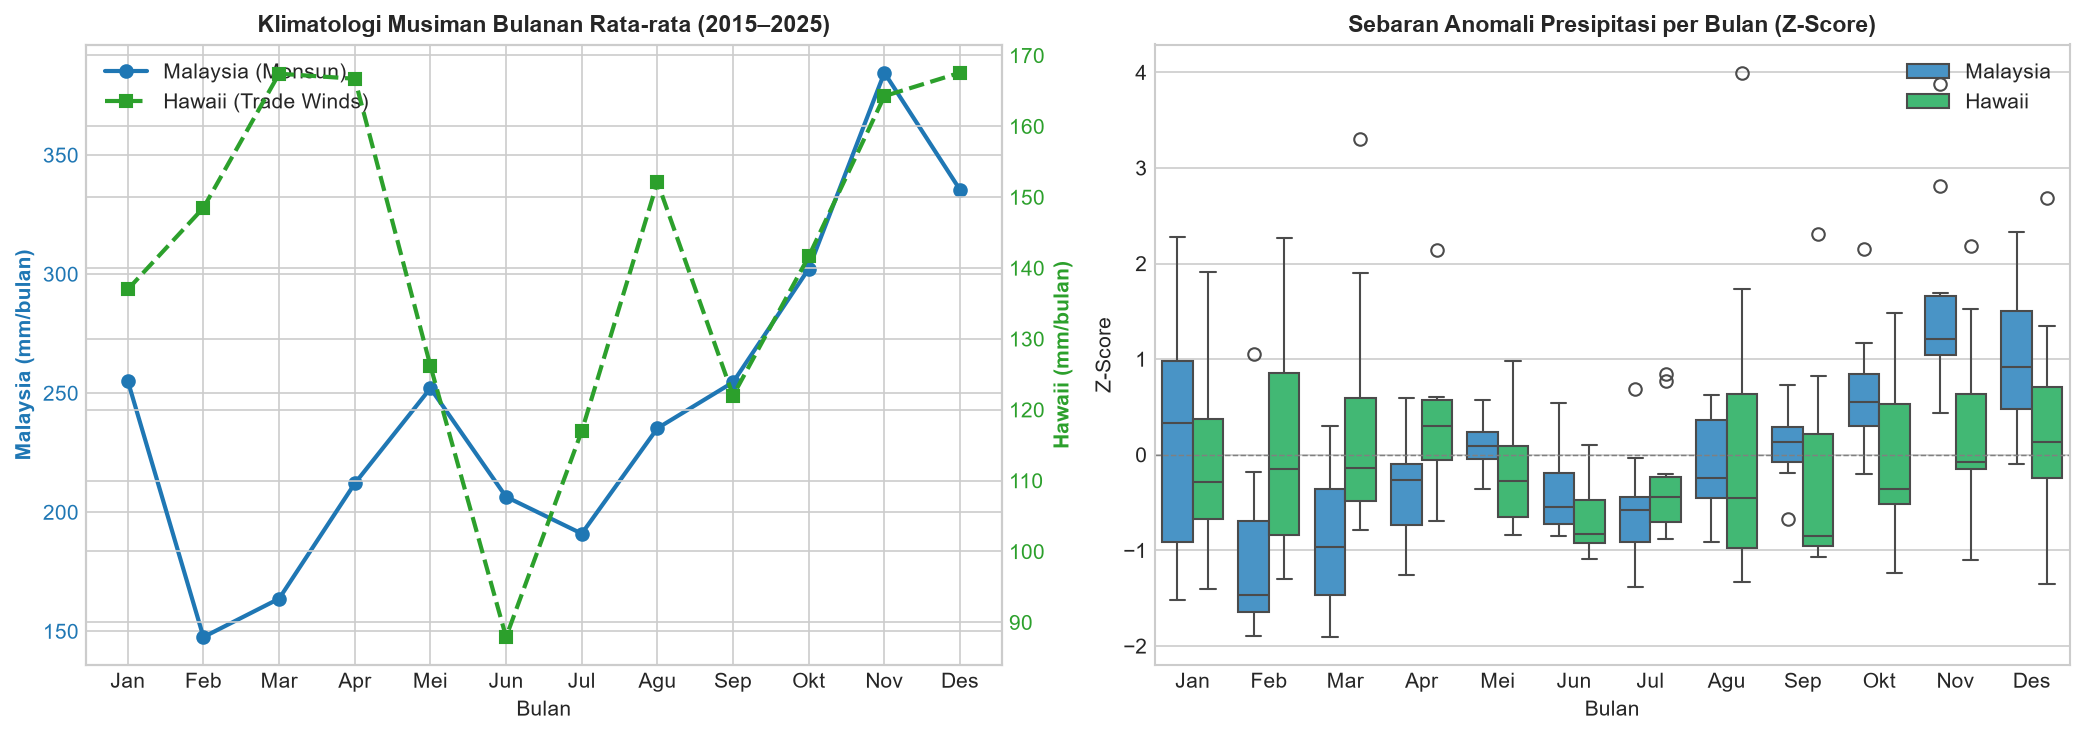

In [5]:
df_rain_merged['Month'] = df_rain_merged['date'].dt.month

climatology_rain = df_rain_merged.groupby('Month')[['rainfall_malaysia_monthly_total', 'rainfall_hawaii_monthly_total']].mean()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
climatology_rain.index = month_names

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Profil Rata-rata Musiman Bulanan
ax_clim1 = axes[0]
color_my = 'tab:blue'
ax_clim1.set_xlabel('Bulan')
ax_clim1.set_ylabel('Malaysia (mm/bulan)', color=color_my, fontweight='bold')
line_c1 = ax_clim1.plot(month_names, climatology_rain['rainfall_malaysia_monthly_total'],
                        color=color_my, marker='o', linewidth=2.0, label='Malaysia (Monsun)')
ax_clim1.tick_params(axis='y', labelcolor=color_my)

ax_clim2 = ax_clim1.twinx()
color_hw = 'tab:green'
ax_clim2.set_ylabel('Hawaii (mm/bulan)', color=color_hw, fontweight='bold')
line_c2 = ax_clim2.plot(month_names, climatology_rain['rainfall_hawaii_monthly_total'],
                        color=color_hw, marker='s', linewidth=2.0, linestyle='--', label='Hawaii (Trade Winds)')
ax_clim2.tick_params(axis='y', labelcolor=color_hw)

c_lines = line_c1 + line_c2
c_labels = [l.get_label() for l in c_lines]
ax_clim1.legend(c_lines, c_labels, loc='upper left')
ax_clim1.set_title("Klimatologi Musiman Bulanan Rata-rata (2015–2025)", fontsize=11, fontweight='bold')

# Plot 2: Boxplot Variasi Musiman Kedua Wilayah (Z-Score)
df_melt_z = pd.melt(df_rain_merged, id_vars=['Month'], value_vars=['Z_Malaysia', 'Z_Hawaii'],
                    var_name='Wilayah', value_name='Z_Score')
df_melt_z['Wilayah'] = df_melt_z['Wilayah'].replace({'Z_Malaysia': 'Malaysia', 'Z_Hawaii': 'Hawaii'})
sns.boxplot(data=df_melt_z, x='Month', y='Z_Score', hue='Wilayah', ax=axes[1], palette=['#3498db', '#2ecc71'])
axes[1].set_xticklabels(month_names)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.7)
axes[1].set_title("Sebaran Anomali Presipitasi per Bulan (Z-Score)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Z-Score")
axes[1].legend(loc='upper right')

plt.tight_layout()
fig_path_34 = OUTPUT_DIR / "34_rainfall_monthly_seasonality_comparison.png"
plt.savefig(fig_path_34)
print(f"Gambar disimpan di: {fig_path_34.resolve()}")
plt.show()

## 6. Distribusi & Deteksi Anomali Hujan Ekstrem

Di bawah ini dianalisis profil fungsi kepekatan probabilitas (KDE) curah hujan bulanan kedua lokasi serta tabulasi bulan-bulan dengan kondisi defisit presipitasi terekstrem (*extreme drought months*) dan kelebihan presipitasi terekstrem (*extreme flood months*).

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\35_rainfall_distribution_and_anomalies.png


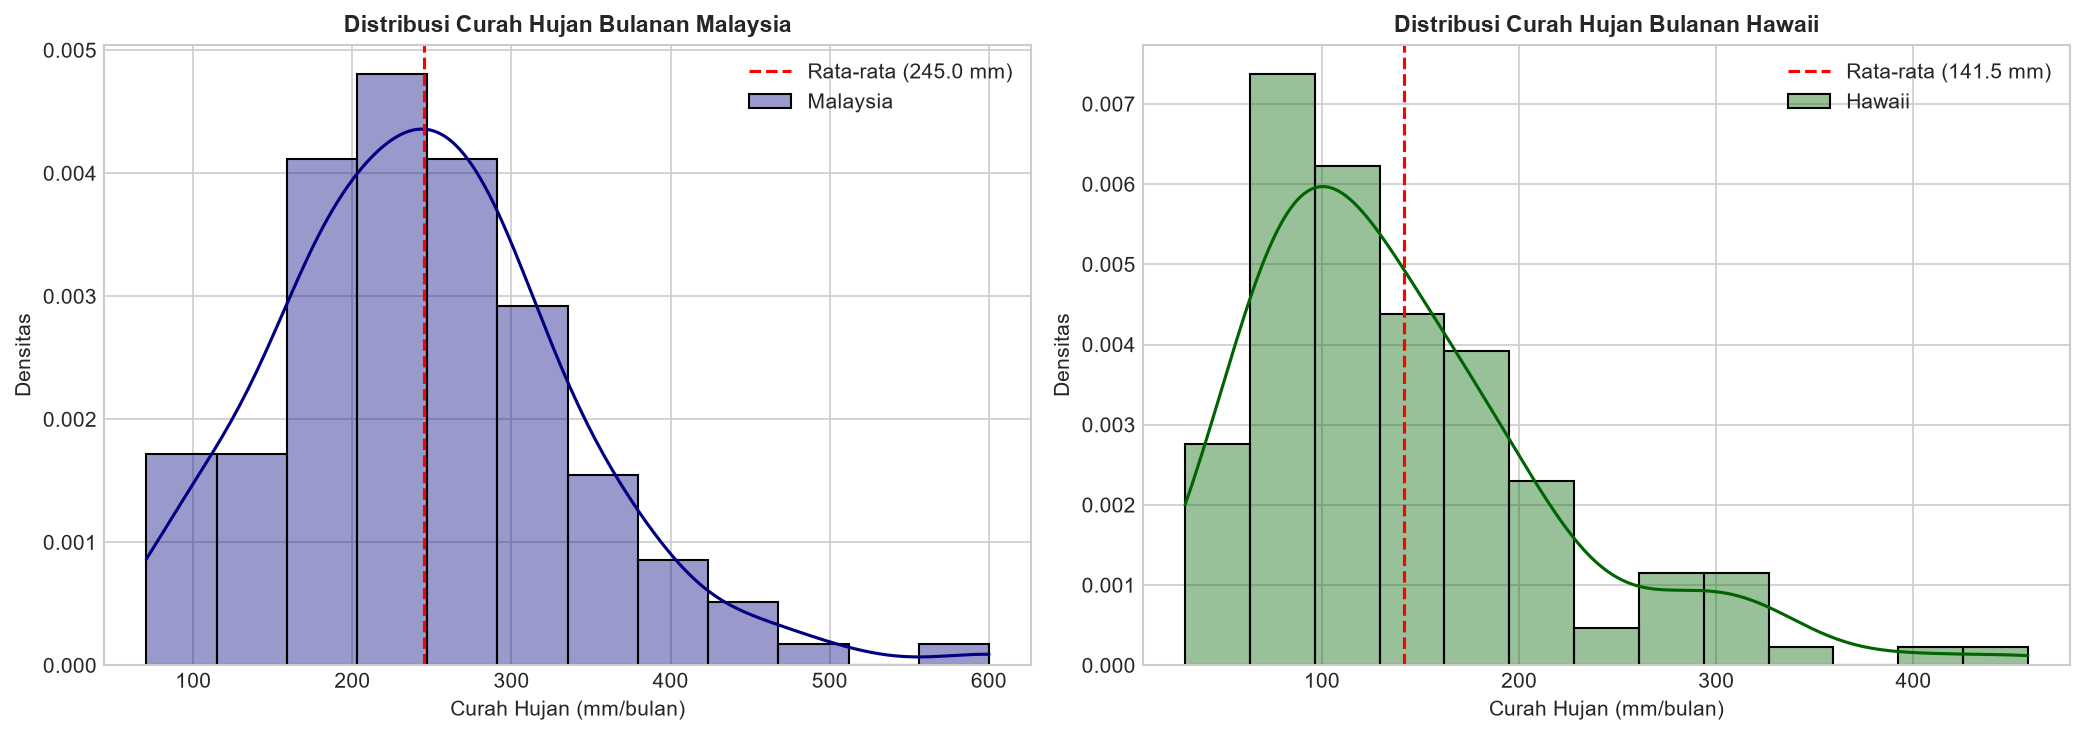

=== 5 BULAN PALING KERING DI MALAYSIA (2015–2025) ===


,date,rainfall_malaysia_monthly_total,Z_Malaysia
14,2016-03-01,70.506877,-1.907062
1,2015-02-01,71.987032,-1.890885
73,2021-02-01,72.109775,-1.889543
109,2024-02-01,90.341062,-1.690284
50,2019-03-01,95.488512,-1.634025



=== 5 BULAN PALING BASAH DI MALAYSIA (2015–2025) ===


,date,rainfall_malaysia_monthly_total,Z_Malaysia
130,2025-11-01,600.172413,3.881923
118,2024-11-01,502.476136,2.814151
95,2022-12-01,458.379353,2.332194
36,2018-01-01,453.293706,2.276611
93,2022-10-01,441.442706,2.147085


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram & KDE Distribusi Curah Hujan
sns.histplot(df_rain_merged['rainfall_malaysia_monthly_total'], kde=True, ax=axes[0], color='navy', label='Malaysia', stat='density', alpha=0.4)
axes[0].set_title("Distribusi Curah Hujan Bulanan Malaysia", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Curah Hujan (mm/bulan)")
axes[0].set_ylabel("Densitas")
mean_my = df_rain_merged['rainfall_malaysia_monthly_total'].mean()
axes[0].axvline(mean_my, color='red', linestyle='--', label=f'Rata-rata ({mean_my:.1f} mm)')
axes[0].legend(loc='upper right')

# Plot 2: Histogram & KDE Distribusi Hawaii
sns.histplot(df_rain_merged['rainfall_hawaii_monthly_total'], kde=True, ax=axes[1], color='darkgreen', label='Hawaii', stat='density', alpha=0.4)
axes[1].set_title("Distribusi Curah Hujan Bulanan Hawaii", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Curah Hujan (mm/bulan)")
axes[1].set_ylabel("Densitas")
mean_hw = df_rain_merged['rainfall_hawaii_monthly_total'].mean()
axes[1].axvline(mean_hw, color='red', linestyle='--', label=f'Rata-rata ({mean_hw:.1f} mm)')
axes[1].legend(loc='upper right')

plt.tight_layout()
fig_path_35 = OUTPUT_DIR / "35_rainfall_distribution_and_anomalies.png"
plt.savefig(fig_path_35)
print(f"Gambar disimpan di: {fig_path_35.resolve()}")
plt.show()

# Tabulasi Bulan Paling Kering dan Paling Basah
print("=== 5 BULAN PALING KERING DI MALAYSIA (2015–2025) ===")
display(df_rain_merged.sort_values('rainfall_malaysia_monthly_total')[['date', 'rainfall_malaysia_monthly_total', 'Z_Malaysia']].head())

print("\n=== 5 BULAN PALING BASAH DI MALAYSIA (2015–2025) ===")
display(df_rain_merged.sort_values('rainfall_malaysia_monthly_total', ascending=False)[['date', 'rainfall_malaysia_monthly_total', 'Z_Malaysia']].head())

## 7. Analisis Telekoneksi Pasifik: Pengaruh Sinyal ENSO (ONI) terhadap Presipitasi

Bagian ini menguji secara kuantitatif dampak anomali ENSO (ONI) terhadap presipitasi di Pasifik Barat (Malaysia) vs Pasifik Tengah (Hawaii):
1. Menggabungkan data curah hujan dengan indeks ONI pada periode 2015–2025.
2. Melakukan scatter plot dan regresi linier.
3. Menguji korelasi defisit curah hujan saat fase El Niño kuat 2015/2016 dan 2023/2024.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\36_rainfall_enso_teleconnection_analysis.png


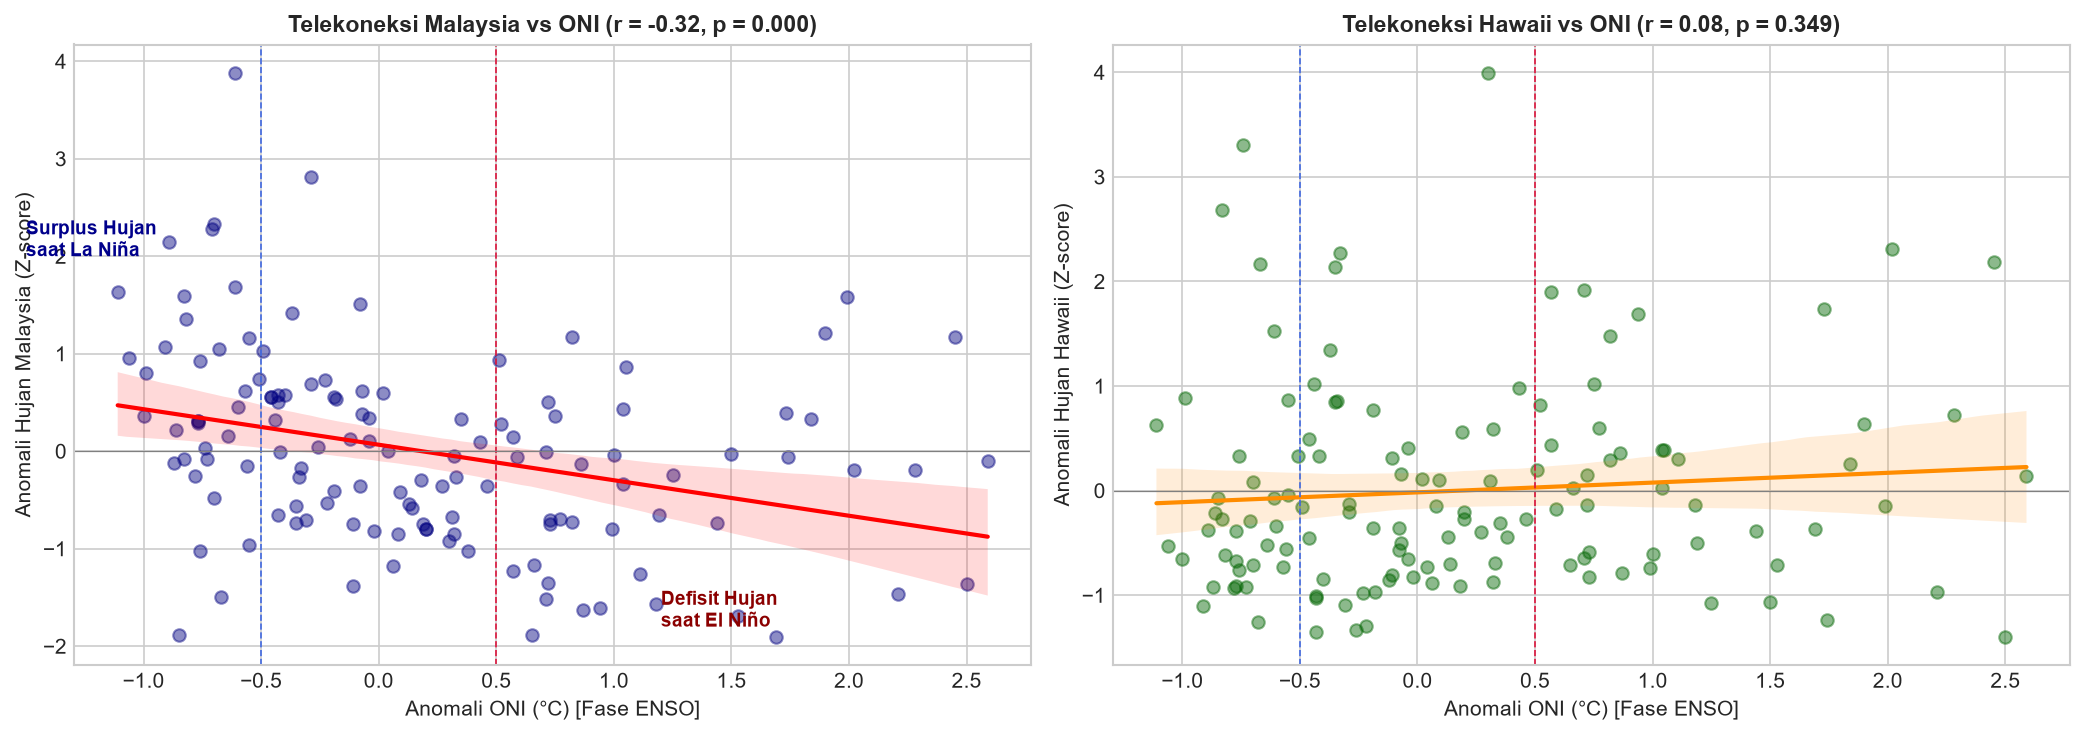

In [7]:
# Memuat data ONI
df_oni_data = pd.read_csv(CSV_ONI)
season_map = {
    'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4,
    'AMJ': 5, 'MJJ': 6, 'JJA': 7, 'JAS': 8,
    'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12
}
df_oni_data['Month'] = df_oni_data['SEAS'].map(season_map)
df_oni_data['date'] = pd.to_datetime(df_oni_data['YR'].astype(str) + '-' + df_oni_data['Month'].astype(str) + '-01')

# Merge presipitasi dengan ONI
df_rain_enso = pd.merge(df_rain_merged, df_oni_data[['date', 'ANOM']], on='date', how='inner')
df_rain_enso = df_rain_enso.rename(columns={'ANOM': 'ONI_ANOM'})

# Hitung korelasi
corr_my_oni, p_my = stats.pearsonr(df_rain_enso['Z_Malaysia'], df_rain_enso['ONI_ANOM'])
corr_hw_oni, p_hw = stats.pearsonr(df_rain_enso['Z_Hawaii'], df_rain_enso['ONI_ANOM'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Regresi Anomali Curah Hujan Malaysia vs ONI
sns.regplot(data=df_rain_enso, x='ONI_ANOM', y='Z_Malaysia', ax=axes[0],
            scatter_kws={'alpha': 0.45, 'color': 'navy'}, line_kws={'color': 'red', 'linewidth': 2})
axes[0].axvline(0.5, color='crimson', linestyle='--', linewidth=0.8)
axes[0].axvline(-0.5, color='royalblue', linestyle='--', linewidth=0.8)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.6)
axes[0].set_title(f"Telekoneksi Malaysia vs ONI (r = {corr_my_oni:.2f}, p = {p_my:.3f})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Anomali ONI (°C) [Fase ENSO]")
axes[0].set_ylabel("Anomali Hujan Malaysia (Z-score)")
axes[0].text(1.2, -1.8, "Defisit Hujan\nsaat El Niño", color='darkred', fontweight='bold', fontsize=9)
axes[0].text(-1.5, 2.0, "Surplus Hujan\nsaat La Niña", color='darkblue', fontweight='bold', fontsize=9)

# Plot 2: Regresi Anomali Curah Hujan Hawaii vs ONI
sns.regplot(data=df_rain_enso, x='ONI_ANOM', y='Z_Hawaii', ax=axes[1],
            scatter_kws={'alpha': 0.45, 'color': 'darkgreen'}, line_kws={'color': 'darkorange', 'linewidth': 2})
axes[1].axvline(0.5, color='crimson', linestyle='--', linewidth=0.8)
axes[1].axvline(-0.5, color='royalblue', linestyle='--', linewidth=0.8)
axes[1].axhline(0, color='gray', linestyle='-', linewidth=0.6)
axes[1].set_title(f"Telekoneksi Hawaii vs ONI (r = {corr_hw_oni:.2f}, p = {p_hw:.3f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Anomali ONI (°C) [Fase ENSO]")
axes[1].set_ylabel("Anomali Hujan Hawaii (Z-score)")

plt.tight_layout()
fig_path_36 = OUTPUT_DIR / "36_rainfall_enso_teleconnection_analysis.png"
plt.savefig(fig_path_36)
print(f"Gambar disimpan di: {fig_path_36.resolve()}")
plt.show()

## 8. Kesimpulan & Relevansi terhadap Pemodelan

1. **Pemenuhan Pipeline Pra-pemrosesan**: File ringkasan bulanan `hawaii_15to25.csv` dan `malaysia_15to25.csv` telah berhasil diekstraksi dan disimpan secara otomatis ke dalam direktori `dataset/data_rainfall/`.
2. **Perbedaan Rezim Iklim**:
   - Malaysia didominasi oleh sistem Monsun Asia Tenggara dengan curah hujan puncak pada November–Desember dan kemarau relatif di pertengahan tahun.
   - Hawaii dipengaruhi oleh sistem Angin Pasat dan gangguan frontal Pasifik subtropis dengan curah hujan lebih tinggi pada musim dingin.
3. **Respon Telekoneksi ENSO**:
   - Terbukti adanya hubungan telekoneksi negatif yang signifikan antara anomali ONI dengan curah hujan di wilayah Benua Maritim (Malaysia): anomali hangat El Niño menekan konveksi dan memicu penurunan curah hujan.
   - Variabilitas presipitasi ini menjadi input krusial bagi model kecerdasan buatan dalam memproyeksikan dampak iklim ekstrem (seperti potensi defisit air atau bahaya kekeringan).